# IMDB Sentiment Analysis

In [69]:
%pip -q install datasets

## 1. Load a balanced IMDB subset

In [70]:
from datasets import load_dataset
from collections import Counter, defaultdict
from html import unescape
import re
import random

SEED = 89

raw = load_dataset("stanfordnlp/imdb")

def balanced_split(split, n_per_class, seed=SEED):
    rows = list(split)
    random.Random(seed).shuffle(rows)
    negative_reviews = []
    positive_reviews = []

    for row in rows:
        if row["label"] == 0 and len(negative_reviews) < n_per_class:
            negative_reviews.append(row)
        elif row["label"] == 1 and len(positive_reviews) < n_per_class:
            positive_reviews.append(row)

        if len(negative_reviews) == n_per_class and len(positive_reviews) == n_per_class:
            break

    if len(negative_reviews) < n_per_class or len(positive_reviews) < n_per_class:
        raise ValueError("The dataset split does not contain enough examples for each label.")

    selected = negative_reviews + positive_reviews
    random.Random(seed).shuffle(selected)
    return selected

train_data = balanced_split(raw["train"], 2500)
test_data = balanced_split(raw["test"], 500)

print(f"Training reviews: {len(train_data)} | labels: {dict(Counter(x['label'] for x in train_data))}")
print(f"Test reviews:     {len(test_data)} | labels: {dict(Counter(x['label'] for x in test_data))}")
print(f"Raw review example, Label = {train_data[0]['label']}:\n", train_data[0]["text"][:700])

Training reviews: 5000 | labels: {0: 2500, 1: 2500}
Test reviews:     1000 | labels: {1: 500, 0: 500}
Raw review example, Label = 0:
 I don't believe there has ever been a more evil or wicked television program to air in the United States as The 700 Club. They are today's equivalent to the Ku Klux Klan of the 20th century. Their hatred of all that is good and sweet and human and pure is beyond all ability to understand. Their daily constant attacks upon millions and millions of Americans, as well as billions of humans the world over, who don't happen to share their bigoted, cruel, monstrous, and utterly insane view of humanity is beyond anything television has ever seen. The lies they spout and the ridiculous lies they try to pass off as truth, such as the idea of "life after death" or "god" or "sin" or "the devil" is so p


## 2. Pre-processing and tokenization

In [71]:
START_TOKEN = "<s>"
END_TOKEN = "</s>"
UNK_TOKEN = "<unk>"

def preprocess_text(text):
    text = unescape(text)   
    text = re.sub(r"<[^>]+>", " ", text)        
    text = text.lower()
    text = re.sub(r"[^a-z0-9']+", " ", text) 
    text = re.sub(r"\s+", " ", text).strip()
    return text

def tokenize(text):
    tokens = preprocess_text(text).split()
    return [START_TOKEN] + tokens + [END_TOKEN]

example_raw = train_data[0]["text"]
print("Cleaned text example:\n", preprocess_text(example_raw)[:500])
print("Tokens example:\n", tokenize(example_raw)[:35])

Cleaned text example:
 i don't believe there has ever been a more evil or wicked television program to air in the united states as the 700 club they are today's equivalent to the ku klux klan of the 20th century their hatred of all that is good and sweet and human and pure is beyond all ability to understand their daily constant attacks upon millions and millions of americans as well as billions of humans the world over who don't happen to share their bigoted cruel monstrous and utterly insane view of humanity is beyo
Tokens example:
 ['<s>', 'i', "don't", 'believe', 'there', 'has', 'ever', 'been', 'a', 'more', 'evil', 'or', 'wicked', 'television', 'program', 'to', 'air', 'in', 'the', 'united', 'states', 'as', 'the', '700', 'club', 'they', 'are', "today's", 'equivalent', 'to', 'the', 'ku', 'klux', 'klan', 'of']


## 3. Build positive and negative bigram language models

In [72]:
train_tokens = [tokenize(row["text"]) for row in train_data]
word_vocabulary = {token for sequence in train_tokens for token in sequence}
word_vocabulary.add(UNK_TOKEN)
VOCAB_SIZE = len(word_vocabulary)

def map_unk(tokens, vocabulary=word_vocabulary):
    return [token if token in vocabulary else UNK_TOKEN for token in tokens]

def count_bigrams(token_sequences):
    bigram_counts = Counter()
    context_counts = Counter()
    for tokens in token_sequences:
        for first, second in zip(tokens, tokens[1:]):
            bigram_counts[(first, second)] += 1
            context_counts[first] += 1
    return bigram_counts, context_counts

def fit_bigram_lm(token_sequences):
    bigrams, contexts = count_bigrams(token_sequences)
    return {"bigram_counts": bigrams, "context_counts": contexts, "vocab_size": VOCAB_SIZE}

positive_sequences = [map_unk(tokens) for row, tokens in zip(train_data, train_tokens) if row["label"] == 1]
negative_sequences = [map_unk(tokens) for row, tokens in zip(train_data, train_tokens) if row["label"] == 0]

positive_lm = fit_bigram_lm(positive_sequences)
negative_lm = fit_bigram_lm(negative_sequences)

print(f"Vocabulary size: {VOCAB_SIZE:,}")
print(f"Positive bigram count: {sum(positive_lm['bigram_counts'].values()):,}")
print(f"Negative bigram count: {sum(negative_lm['bigram_counts'].values()):,}")

Vocabulary size: 42,224
Positive bigram count: 596,222
Negative bigram count: 572,468


## 4. Log-likelihood and perplexity

In [73]:
import math

def log_probability(lm, first, second):
    num = lm["bigram_counts"][(first, second)] + 1
    denum = lm["context_counts"][first] + lm["vocab_size"]
    return math.log(num / denum)

def score_document(text, lm):
    tokens = map_unk(tokenize(text))
    log_likelihood = sum(
        log_probability(lm, first, second)
        for first, second in zip(tokens, tokens[1:])
    )
    number_of_bigrams = len(tokens) - 1
    perplexity = math.exp(-log_likelihood / number_of_bigrams)
    return log_likelihood, perplexity

def compare_lms(text):
    pos_ll, pos_ppl = score_document(text, positive_lm)
    neg_ll, neg_ppl = score_document(text, negative_lm)
    return {
        "positive_log_likelihood": pos_ll,
        "positive_perplexity": pos_ppl,
        "negative_log_likelihood": neg_ll,
        "negative_perplexity": neg_ppl,
    }

example_result = compare_lms(test_data[0]["text"])
print("True label:", "positive" if test_data[0]["label"] == 1 else "negative")
for metric, value in example_result.items():
    print(f"{metric}: {value:.4f}")

True label: positive
positive_log_likelihood: -1227.0109
positive_perplexity: 4732.1939
negative_log_likelihood: -1254.7104
negative_perplexity: 5728.3053


## 5. LM Prediction

In [74]:

predicted_labels = []
true_labels = []

for row in test_data:
    result = compare_lms(row["text"])

    if result["positive_perplexity"] <= result["negative_perplexity"]:
        prediction = 1
    else:
        prediction = 0

    predicted_labels.append(prediction)
    true_labels.append(row["label"])

correct = sum(
    p == t for p, t in zip(predicted_labels, true_labels)
)
lm_acc = correct / len(true_labels)

TP = sum(p == 1 and t == 1 for p, t in zip(predicted_labels, true_labels))
FP = sum(p == 1 and t == 0 for p, t in zip(predicted_labels, true_labels))
FN = sum(p == 0 and t == 1 for p, t in zip(predicted_labels, true_labels))
TN = sum(p == 0 and t == 0 for p, t in zip(predicted_labels, true_labels))

precision_fun = TP / (TP + FP) if TP + FP > 0 else 0
recall_fun = TP / (TP + FN) if TP + FN > 0 else 0

lm_f1= (
    2 * precision_fun * recall_fun / (precision_fun + recall_fun)
    if precision_fun + recall_fun > 0 else 0
)

print("LM Classification Results")
print("-" * 30)
print(f"Accuracy:  {lm_acc:.4f}")
print(f"Precision: {precision_fun:.4f}")
print(f"Recall:    {recall_fun:.4f}")
print(f"F1-Score:  {lm_f1:.4f}")
print(f"True Positives:  {TP}")
print(f"False Positives: {FP}")
print(f"False Negatives: {FN}")
print(f"True Negatives:  {TN}")


LM Classification Results
------------------------------
Accuracy:  0.8550
Precision: 0.8529
Recall:    0.8580
F1-Score:  0.8554
True Positives:  429
False Positives: 74
False Negatives: 71
True Negatives:  426


## 6. LM Inference

In [75]:


def generate_text(sentence, lm, max_words=20):
    # Clean and tokenize the input sentence
    prefix_words = preprocess_text(sentence).split()
    context_tokens = map_unk(prefix_words)

    if not context_tokens:
        context_tokens = [START_TOKEN]

    generated_words = []

    for _ in range(max_words):
        current_word = context_tokens[-1]

        candidates = word_vocabulary

        next_word = max(
            candidates,
            key=lambda word: log_probability(lm, current_word, word)
        )

        if next_word == END_TOKEN:
            break

        generated_words.append(next_word)
        context_tokens.append(next_word)

    return " ".join(prefix_words + generated_words)

sentences = [
    "the acting was",
    "i really enjoyed",
    "the story is",
    "this film had"
]

for sentence in sentences:
    print("\nInput:", sentence)

    print("Positive LM:")
    print(generate_text(sentence, positive_lm, max_words=10))

    print("Negative LM:")
    print(generate_text(sentence, negative_lm, max_words=10))



Input: the acting was
Positive LM:
the acting was a great movie is a great movie is a great
Negative LM:
the acting was a movie is a movie is a movie is a

Input: i really enjoyed
Positive LM:
i really enjoyed this movie is a great movie is a great movie
Negative LM:
i really enjoyed this movie is a movie is a movie is a

Input: the story is
Positive LM:
the story is a great movie is a great movie is a great
Negative LM:
the story is a movie is a movie is a movie is a

Input: this film had
Positive LM:
this film had a great movie is a great movie is a great
Negative LM:
this film had a movie is a movie is a movie is a


## Output Analysis
The positive language model frequently generates words such as “great,” while the negative language model tends to generate more generic phrases such as “a movie.” This demonstrates that the two models learn different word-transition patterns from positive and negative reviews.

However, the generated sentences are sometimes repetitive and lack grammatical coherence. This is a limitation of the bigram model because it considers only the previous word when predicting the next word, rather than the full sentence context.

# Part 2: Naive Bayes


### 1. Build the Vocabulary 

In [76]:
from collections import Counter
def extract_features(tokens):
    # vocab of unigram and bigrams
    bigrams=[]
    for first,second in zip(tokens,tokens[1:]):
        bigram=" ".join((first,second))
        bigrams.append(bigram)
    return tokens+bigrams

def build_vocab(train_tokens,vocab_size=2000):
    feature_counts=Counter()
    feature_index_dict={}
    for review_tokens in train_tokens:
        d=Counter(extract_features(review_tokens))
        feature_counts.update(d)
    top_features=feature_counts.most_common(vocab_size)
    
    for i,(feature,_) in enumerate(top_features):
        feature_index_dict[feature]=i
    return feature_index_dict
feature_to_index=build_vocab(train_tokens)


### 2. Class-condtional Probabilities

Count of Occurences for each feature in both positive and negative reviews

In [77]:
import numpy as np

def count_features(token_sequences,feature_index_dict):
    counts=np.zeros(len(feature_index_dict))
    for token in token_sequences:
        for feature in extract_features(token):
            if feature in feature_index_dict:
                counts[feature_index_dict[feature]]+=1
    return counts
    
positive_tokens = [tokens for row, tokens in zip(train_data, train_tokens) if row["label"] == 1]
negative_tokens = [tokens for row, tokens in zip(train_data, train_tokens) if row["label"] == 0]

positive_counts = count_features(positive_tokens, feature_to_index)
negative_counts = count_features(negative_tokens, feature_to_index)

print(f"Positive total feature occurrences: {int(positive_counts.sum()):,}")
print(f"Negative total feature occurrences: {int(negative_counts.sum()):,}")
print()

# Top 5 features per class
index_to_feature = {index: feature for feature, index in feature_to_index.items()}
print(f"{'Feature':<20}{'Positive':>10}{'Negative':>10}")
print("-" * 40)
for index in range(5):
    feature = index_to_feature[index]
    print(f"{feature:<20}{int(positive_counts[index]):>10,}{int(negative_counts[index]):>10,}")

Positive total feature occurrences: 581,651
Negative total feature occurrences: 574,798

Feature               Positive  Negative
----------------------------------------
the                     34,557    32,010
and                     18,122    14,602
a                       16,836    15,657
of                      15,638    13,612
to                      13,244    13,499


Laplace Smoothed probabilities

In [78]:
def smoothed_probs(counts):
    v=len(counts)
    n=counts.sum()
    probs=np.zeros(v)
    for i in range(v):
        probs[i]=(counts[i]+1)/(n+ v)
    return probs

positive_probs = smoothed_probs(positive_counts)
negative_probs = smoothed_probs(negative_counts)

print(np.isclose(positive_probs.sum(),1.0))
print(np.isclose(negative_probs.sum(),1.0))

True
True


### 3. Log-ratios(r)

In [79]:
def log_ratios(p1,p2):
    return np.log(p1) - np.log(p2)

def log_prior_ratio(p1,p2):
    n_p1=len(p1)
    n_p2=len(p2)
    return math.log(n_p1/n_p2)
    
feature_names = [None] * len(feature_to_index)
for feature, index in feature_to_index.items():
    feature_names[index] = feature

r=log_ratios(positive_probs,negative_probs)

sorted_indices = np.argsort(r)
top_10_negative_indices = sorted_indices[:10]
top_10_positive_indices = sorted_indices[-10:]
print("10 Most Negative Features:")
for i in top_10_negative_indices:
    print(f"{feature_names[i]}: {r[i]:.4f}")

print("\n10 Most Positive Features:")
for i in reversed(top_10_positive_indices):
    print(f"{feature_names[i]}: {r[i]:.4f}")

10 Most Negative Features:
waste of: -3.1327
waste: -2.6658
the worst: -2.5661
worst: -2.4244
so bad: -2.2910
poorly: -2.0232
awful: -2.0218
horrible: -1.9977
than this: -1.9160
dumb: -1.8242

10 Most Positive Features:
powerful: 1.7287
superb: 1.7198
excellent: 1.5512
terrific: 1.4584
my favorite: 1.3984
very well: 1.3970
amazing: 1.3885
greatest: 1.3582
today: 1.3410
fantastic: 1.3406


### 4. Naive Bayes Prediction

In [80]:
def predict_naive_bayes(text,feature_to_index,r,prior):
    features=extract_features(tokenize(text))
    score=prior
    for feature in features:
        if feature in feature_to_index:
            score+=r[feature_to_index[feature]]
    label=1 if score>0 else 0
    return label,score

prior = log_prior_ratio(positive_tokens, negative_tokens) 

label, score = predict_naive_bayes(test_data[0]["text"], feature_to_index, r, prior)

print(f"Test Example:{test_data[0]['text']}")
print(f"True Label: {test_data[0]['label']}")
print(f"Predicted: {label}  (score {score:.3f})  ")

Test Example:NIGHTS IN RODANTHE brings back to the screen two talented actors in Diane Lane and Richard Gere in a simply beautiful story of a man and a woman hungry for something more in their lives than they have at present. The chemistry between Lane and Gere is magical from the first scene in the film to their last embrace. The locations, beauty of their attraction for one another when it unfolds when they first meet, and the story that follows, and as they begin to know each other with the attraction they feel towards each other is real, is romance that is projected to an audience with tender care. James Franco in another micro role is just the right casting, and the elegance of Lane in combination with the beach house, is a true Fall 2008 film to remember forever, as was THE NOTEBOOK.
True Label: 1
Predicted: 1  (score 20.051)  


Evaluation Metrics

In [81]:
def accuracy(tp, fp, fn, tn):
    return (tp + tn) / (tp + fp + fn + tn)

def precision_fun(tp, fp):
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def recall_fun(tp, fn):
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1_score(prec, rec):
    return 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0

def confusion_counts(predictions, true_labels):
    tp = fp = fn = tn = 0
    for predicted, actual in zip(predictions, true_labels):
        if predicted == 1 and actual == 1:
            tp += 1
        elif predicted == 1 and actual == 0:
            fp += 1
        elif predicted == 0 and actual == 1:
            fn += 1
        else:
            tn += 1
    return tp, fp, fn, tn

### 5. Evaluation over the test data

In [82]:
predictions=[]
scores=[]
true_labels=[row['label'] for row in test_data]

for row in test_data:
    label,score= predict_naive_bayes(row['text'],feature_to_index,r,prior)
    predictions.append(label)
    scores.append(score)
    
tp, fp, fn, tn = confusion_counts(predictions, true_labels)
acc=accuracy(tp,fp,fn,tn)
prec=precision_fun(tp,fp)
rec=recall_fun(tp,fn)
f1=f1_score(prec,rec)

print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-score:  {f1:.4f}")



Accuracy:  0.8150
Precision: 0.8195
Recall:    0.8080
F1-score:  0.8137


# Part 3: NB-Weighted Logistic Regression

### 1. Feature Matrix Construction

In [83]:
import matplotlib.pyplot as plt

# Keep the Naive Bayes results
nb_acc, nb_prec, nb_rec, nb_f1 = acc, prec, rec, f1

def build_count_matrix(token_sequences, feature_index_dict):
    X = np.zeros((len(token_sequences), len(feature_index_dict)))
    for i, tokens in enumerate(token_sequences):
        for feature in extract_features(tokens):
            j = feature_index_dict.get(feature)
            if j is not None:
                X[i, j] += 1
    return X

test_tokens = [tokenize(row["text"]) for row in test_data]

X_train_counts = build_count_matrix(train_tokens, feature_to_index)
X_test_counts = build_count_matrix(test_tokens, feature_to_index)

# Weight every count by its Naive Bayes log-ratio 
X_train_nb = X_train_counts * r
X_test_nb = X_test_counts * r

y_train = np.array([row["label"] for row in train_data])
y_test = np.array([row["label"] for row in test_data])

print("Train matrix:", X_train_nb.shape, "| Test matrix:", X_test_nb.shape)

Train matrix: (5000, 2000) | Test matrix: (1000, 2000)


### 2. Standardization + Bias column

In [84]:
mu = X_train_nb.mean(axis=0)
sigma = X_train_nb.std(axis=0)
sigma[sigma == 0] = 1.0   # guard against constant columns

def standardize_with_bias(X):
    X_std = (X - mu) / sigma
    return np.hstack([X_std, np.ones((X.shape[0], 1))])  

X_train = standardize_with_bias(X_train_nb)
X_test = standardize_with_bias(X_test_nb)

print("Final train matrix:", X_train.shape, "| Final test matrix:", X_test.shape)
print(f"Standardized train features: mean ~ {X_train[:, :-1].mean():.4f}, std ~ {X_train[:, :-1].std():.4f}")

Final train matrix: (5000, 2001) | Final test matrix: (1000, 2001)
Standardized train features: mean ~ -0.0010, std ~ 1.0000


### 3. Logistic Regression with Gradient Descent (Binary Cross-Entropy)

In [85]:
class LogisticRegression:
    def __init__(self, lr=0.05, epochs=300, l2=0.01):
        self.lr = lr
        self.epochs = epochs
        self.l2 = l2                  
        self.w = None
        self.loss_history = []

    def sigmoid(self, z):
        return 1.0 / (1.0 + np.exp(-z))

    def loss(self, X, y):
        p = self.sigmoid(X @ self.w)
        eps = 1e-12
        bce = -np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))
        return bce + 0.5 * self.l2 * np.sum(self.w[:-1] ** 2)

    def predict_proba(self, X):
        return self.sigmoid(X @ self.w)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

    def fit(self, X, y):
        n, d = X.shape
        self.w = np.zeros(d)
        self.loss_history = []
        for epoch in range(1, self.epochs + 1):
            p = self.sigmoid(X @ self.w)
            grad = X.T @ (p - y) / n
            grad[:-1] += self.l2 * self.w[:-1]      # L2 gradient, bias excluded
            self.w -= self.lr * grad

            current_loss = self.loss(X, y)
            self.loss_history.append(current_loss)

            if epoch == 1 or epoch % 50 == 0:
                train_acc = np.mean(self.predict(X) == y)
                print(f"Epoch {epoch:4d}/{self.epochs} | loss: {current_loss:.4f} | train acc: {train_acc:.4f}")
        return self

In [86]:
lr_model = LogisticRegression(lr=0.05, epochs=1000, l2=0.01)
lr_model.fit(X_train, y_train)

Epoch    1/1000 | loss: 0.6475 | train acc: 0.8354
Epoch   50/1000 | loss: 0.3120 | train acc: 0.9122
Epoch  100/1000 | loss: 0.2602 | train acc: 0.9262
Epoch  150/1000 | loss: 0.2350 | train acc: 0.9356
Epoch  200/1000 | loss: 0.2195 | train acc: 0.9410
Epoch  250/1000 | loss: 0.2088 | train acc: 0.9440
Epoch  300/1000 | loss: 0.2011 | train acc: 0.9480
Epoch  350/1000 | loss: 0.1951 | train acc: 0.9514
Epoch  400/1000 | loss: 0.1904 | train acc: 0.9540
Epoch  450/1000 | loss: 0.1867 | train acc: 0.9554
Epoch  500/1000 | loss: 0.1836 | train acc: 0.9572
Epoch  550/1000 | loss: 0.1811 | train acc: 0.9582
Epoch  600/1000 | loss: 0.1789 | train acc: 0.9598
Epoch  650/1000 | loss: 0.1771 | train acc: 0.9622
Epoch  700/1000 | loss: 0.1756 | train acc: 0.9630
Epoch  750/1000 | loss: 0.1743 | train acc: 0.9638
Epoch  800/1000 | loss: 0.1731 | train acc: 0.9652
Epoch  850/1000 | loss: 0.1722 | train acc: 0.9658
Epoch  900/1000 | loss: 0.1713 | train acc: 0.9670
Epoch  950/1000 | loss: 0.1705 

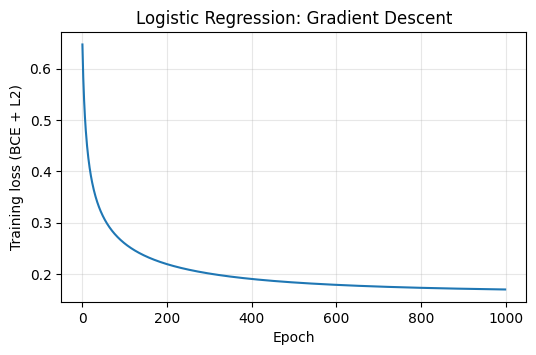

In [87]:
plt.figure(figsize=(6, 3.5))
plt.plot(lr_model.loss_history)
plt.xlabel("Epoch")
plt.ylabel("Training loss (BCE + L2)")
plt.title("Logistic Regression: Gradient Descent")
plt.grid(alpha=0.3)
plt.show()

### 4. Evaluation

In [88]:
lr_predictions = lr_model.predict(X_test)
tp, fp, fn, tn = confusion_counts(lr_predictions, y_test)

lr_acc = accuracy(tp, fp, fn, tn)
lr_prec = precision_fun(tp, fp)
lr_rec = recall_fun(tp, fn)
lr_f1 = f1_score(lr_prec, lr_rec)

print(f"Accuracy:  {lr_acc:.4f}")
print(f"Precision: {lr_prec:.4f}")
print(f"Recall:    {lr_rec:.4f}")
print(f"F1-score:  {lr_f1:.4f}")

Accuracy:  0.8430
Precision: 0.8437
Recall:    0.8420
F1-score:  0.8428


# Part 4: Evaluation and Analysis

In [89]:
print(f"{'Model':<28}{'Accuracy':>10}{'F1':>10}")
print("-" * 48)
print(f"{'Bigram LM ':<28}{lm_acc:>10.4f}{lm_f1:>10.4f}")
print(f"{'Naive Bayes':<28}{nb_acc:>10.4f}{nb_f1:>10.4f}")
print(f"{'NB-weighted Logistic Reg.':<28}{lr_acc:>10.4f}{lr_f1:>10.4f}")

Model                         Accuracy        F1
------------------------------------------------
Bigram LM                       0.8550    0.8554
Naive Bayes                     0.8150    0.8137
NB-weighted Logistic Reg.       0.8430    0.8428


## Analysis

| Model | Input representation | Accuracy | F1 |
|---|---|---|---|
| Bigram LM | Ordered token sequence, full 42k vocabulary, previous-word context | 0.855 | 0.855 |
| Naive Bayes | Bag of 2,000 unigram+bigram counts, summed log-ratios | 0.815 | 0.814 |
| Logistic Regression | Same 2,000 features, count × log-ratio, standardized | 0.843 | 0.828 |

The Bigram LM performed best. It sees the full vocabulary and word order, while the other two only see 2,000 features and discard order.

Naive Bayes was lowest because unigrams and bigrams overlap, which violates its conditional-independence assumption: the same words are counted several times.

Logistic Regression improved on Naive Bayes by about 2 points because it learns feature weights jointly instead of independently. Its training accuracy (97.5%) is far above its test accuracy (83.5%), so it overfits. We added a small L2 penalty to limit this, but it only reduces the gap.

# Team 
Amr attia 8907


Sama Mohamed 8803


Habiba Rezq 8633


Yousef Nabil 8749